In [1]:
import pandas as pd
import polars as pl
import numpy as np
from tqdm.auto import tqdm
from matplotlib import pyplot as plt
import pickle
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
import warnings

warnings.filterwarnings("ignore")
pd.options.display.max_columns = None

In [2]:
class CONFIG:
    seed = 42
    target_col = "responder_6"
    feature_cols = (
        ["symbol_id", "time_id"]
        + [f"feature_{idx:02d}" for idx in range(79)]
        + [f"responder_{idx}_lag_1" for idx in range(9)]
    )
    categorical_cols = []

In [3]:
train = (
    pl.scan_parquet(
        "./input/js24-preprocessing-create-lags/training.parquet",
        n_rows=200000,
    )
    .collect()
    .to_pandas()
)
valid = (
    pl.scan_parquet(
        "./input/js24-preprocessing-create-lags/validation.parquet",
        n_rows=10000,
    )
    .collect()
    .to_pandas()
)
train = pd.concat([train, valid]).reset_index(drop=True)
train.shape, valid.shape

((210000, 104), (10000, 104))

In [4]:
def get_model(seed):
    XGB_Params = {
        "learning_rate": 0.01,
        "max_depth": 10,
        "n_estimators": 1000,
        "reg_alpha": 1,
        "reg_lambda": 5,
        "random_state": seed,
        "tree_method": "hist",
    }
    XGB_Model = XGBRegressor(**XGB_Params)
    return XGB_Model

In [5]:
X_train = train[CONFIG.feature_cols]
y_train = train[CONFIG.target_col]
w_train = train["weight"]
X_valid = valid[CONFIG.feature_cols]
y_valid = valid[CONFIG.target_col]
w_valid = valid["weight"]

X_train.shape, y_train.shape, w_train.shape, X_valid.shape, y_valid.shape, w_valid.shape

((210000, 90), (210000,), (210000,), (10000, 90), (10000,), (10000,))

In [6]:
model = get_model(CONFIG.seed)
model.fit(X_train, y_train, sample_weight=w_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=10, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [7]:
y_pred_train1 = model.predict(X_train.iloc[: X_train.shape[0] // 2])
y_pred_train2 = model.predict(X_train.iloc[X_train.shape[0] // 2 :])
train_score = r2_score(
    y_train,
    np.concatenate([y_pred_train1, y_pred_train2], axis=0),
    sample_weight=w_train,
)
train_score

0.7201435565948486

In [8]:
y_pred_valid = model.predict(X_valid)
valid_score = r2_score(y_valid, y_pred_valid, sample_weight=w_valid)
valid_score

0.8771950006484985

In [9]:
y_means = {symbol_id: -1 for symbol_id in range(39)}
for symbol_id, gdf in train[["symbol_id", CONFIG.target_col]].groupby(
    "symbol_id"
):
    y_mean = gdf[CONFIG.target_col].mean()
    y_means[symbol_id] = y_mean
    print(f"symbol_id = {symbol_id}, y_means = {y_mean:.5f}")

symbol_id = 0, y_means = 0.05676
symbol_id = 1, y_means = 0.06058
symbol_id = 2, y_means = -0.01117
symbol_id = 3, y_means = -0.14348
symbol_id = 4, y_means = 0.01888
symbol_id = 5, y_means = -0.00382
symbol_id = 6, y_means = -0.00852
symbol_id = 7, y_means = 0.04512
symbol_id = 8, y_means = -0.04482
symbol_id = 9, y_means = 0.03544
symbol_id = 10, y_means = -0.00508
symbol_id = 11, y_means = -0.01087
symbol_id = 12, y_means = -0.12038
symbol_id = 13, y_means = 0.05729
symbol_id = 14, y_means = 0.09796
symbol_id = 15, y_means = -0.02498
symbol_id = 16, y_means = 0.01498
symbol_id = 17, y_means = -0.04939
symbol_id = 18, y_means = -0.00681
symbol_id = 19, y_means = -0.16133
symbol_id = 20, y_means = 0.00846
symbol_id = 21, y_means = 0.09608
symbol_id = 22, y_means = -0.16713
symbol_id = 23, y_means = 0.03350
symbol_id = 24, y_means = -0.03003
symbol_id = 25, y_means = 0.01990
symbol_id = 26, y_means = 0.01987
symbol_id = 27, y_means = -0.08261
symbol_id = 28, y_means = 0.01845
symbol_id

In [10]:
cv_detail = {symbol_id: 0 for symbol_id in range(39)}
for symbol_id, gdf in valid.groupby("symbol_id"):
    X_valid = gdf[CONFIG.feature_cols]
    y_valid = gdf[CONFIG.target_col]
    w_valid = gdf["weight"]
    y_pred_valid = model.predict(X_valid)
    score = r2_score(y_valid, y_pred_valid, sample_weight=w_valid)
    cv_detail[symbol_id] = score

    print(f"symbol_id = {symbol_id}, score = {score:.5f}")

symbol_id = 0, score = 0.76106
symbol_id = 1, score = 0.90978
symbol_id = 2, score = 0.90126
symbol_id = 3, score = 0.87756
symbol_id = 4, score = 0.77108
symbol_id = 5, score = 0.87430
symbol_id = 6, score = 0.79615
symbol_id = 7, score = 0.76816
symbol_id = 8, score = 0.93223
symbol_id = 9, score = 0.88015
symbol_id = 10, score = 0.89022
symbol_id = 11, score = 0.91107
symbol_id = 12, score = 0.94739
symbol_id = 13, score = 0.92885
symbol_id = 14, score = 0.86026
symbol_id = 15, score = 0.86450
symbol_id = 16, score = 0.93882
symbol_id = 17, score = 0.81411
symbol_id = 18, score = 0.62901
symbol_id = 19, score = 0.90758
symbol_id = 20, score = 0.84720
symbol_id = 21, score = 0.76335
symbol_id = 22, score = 0.64030
symbol_id = 23, score = 0.76245
symbol_id = 24, score = 0.72885
symbol_id = 25, score = 0.94752
symbol_id = 26, score = 0.35208
symbol_id = 27, score = 0.79569
symbol_id = 28, score = 0.84539
symbol_id = 29, score = 0.77600
symbol_id = 30, score = 0.81010
symbol_id = 31, sc

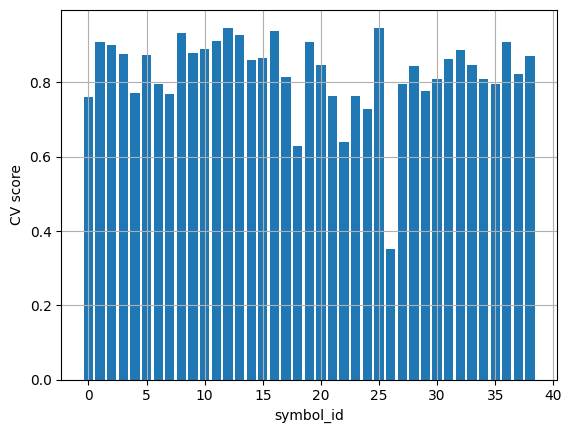

In [11]:
sids = list(cv_detail.keys())
plt.bar(sids, [cv_detail[sid] for sid in sids])
plt.grid()
plt.xlabel("symbol_id")
plt.ylabel("CV score")
plt.show()

In [12]:
result = {
    "model": model,
    "cv": valid_score,
    "cv_detail": cv_detail,
    "y_mean": y_means,
}
with open("./input/js24-trained-gbdt-model/result.pkl", "wb") as fp:
    pickle.dump(result, fp)